# 实验5D：人脸检测与条件压力测试（部分完成）

身份识别实现被自动审批拒绝；本Notebook仅完成人脸检测与光照、平面旋转、遮挡条件测试。未完成CNN身份特征、身份分类及其Accuracy/Precision/Recall/F1，不将检测率作为身份识别准确率。

In [1]:
EXPERIMENT='exp5D'
from pathlib import Path
import os, sys, random, json, time, copy, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
ROOT=Path.cwd() if (Path.cwd()/'exp5').is_dir() else Path.cwd().parent
BASE=ROOT/'exp5'; DATA=BASE/'data'; CACHE=BASE/'.cache'; RESULT=BASE/'results'/EXPERIMENT
for p in [DATA,CACHE,RESULT]: p.mkdir(parents=True,exist_ok=True)
sys.path.insert(0,str(ROOT/'exp4/.cache/python'))
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(4)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'font.sans-serif':['Microsoft YaHei','SimHei','DejaVu Sans'],'axes.unicode_minus':False,'figure.dpi':110})
SENTENCE='今天终于通过了考试，我真的很开心！'
print(sys.executable,torch.__version__,device)
def savefig(name):
    plt.savefig(RESULT/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def metrics(y,p):
    pr,re,f,_=precision_recall_fscore_support(y,p,labels=[0,1,2],average='macro',zero_division=0)
    return dict(Accuracy=accuracy_score(y,p),Precision_macro=pr,Recall_macro=re,F1_macro=f)
def code_image(code):
    fig,ax=plt.subplots(figsize=(12,max(3,len(code.splitlines())*.23))); ax.axis('off')
    ax.text(0,1,code,va='top',fontfamily='monospace',fontsize=9,transform=ax.transAxes); savefig('model_code')


E:\CODE\DeepLearning-exp\.cache\exp5-env\Scripts\python.exe 2.14.1+cu130 cuda


## 数据与方法
[LFW公开数据镜像](https://huggingface.co/datasets/bitmind/lfw)固定随机抽300张，仅用于人脸检测。[OpenCV预训练YuNet检测器](https://github.com/opencv/opencv_zoo/tree/main/models/face_detection_yunet)，置信度阈值0.8、NMS阈值0.3。光照用像素缩放，姿态仅模拟平面倾斜，遮挡是固定灰块；不能代表真实侧脸和真实遮挡。数据原本已以人脸为中心，不能推断实际场景性能。

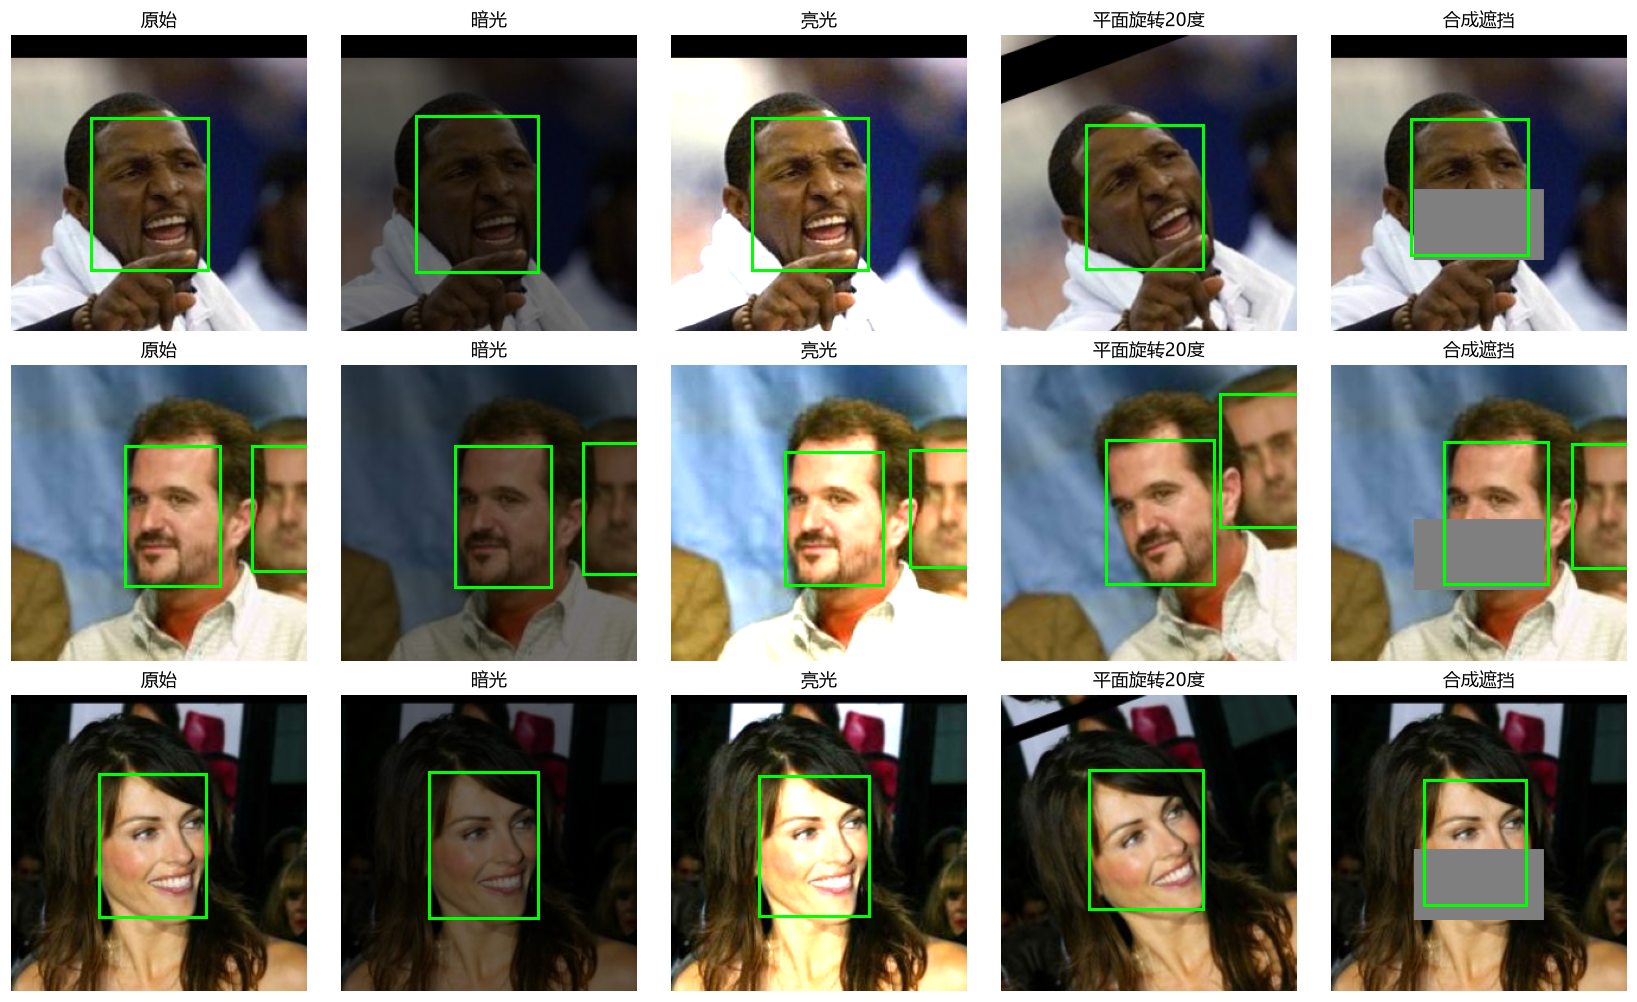

,condition,n,images_with_detection,detection_coverage
0,原始,300,300,1.000000
1,暗光,300,300,1.000000
2,亮光,300,299,0.996667
3,平面旋转20度,300,299,0.996667
4,合成遮挡,300,299,0.996667


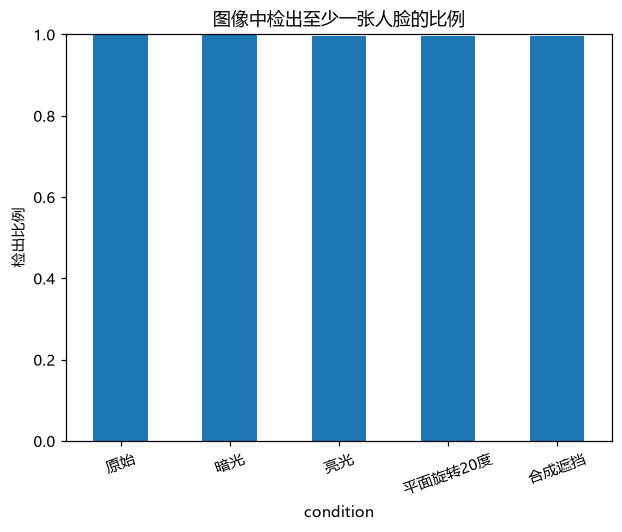

没有人工框标注，以上不是检测精确率、召回率或身份识别指标。


In [2]:
import cv2, requests, io
from PIL import Image
# 原figshare入口403，使用同一LFW数据集的13233张图像Parquet镜像。
path=DATA/'lfw.parquet'
if not path.exists():
    r=requests.get('https://huggingface.co/datasets/bitmind/lfw/resolve/main/data/train-00000-of-00001.parquet',timeout=180);r.raise_for_status();path.write_bytes(r.content)
lfw=pd.read_parquet(path,columns=['image'])
rng=np.random.default_rng(SEED);indices=np.sort(rng.choice(len(lfw),300,replace=False))
images=np.stack([np.array(Image.open(io.BytesIO(lfw.iloc[i].image['bytes'])).convert('RGB')) for i in indices]);del lfw
pd.DataFrame({'source_index':indices}).to_csv(RESULT/'sample_manifest.csv',index=False)
model_path=CACHE/'face_detection_yunet_2023mar.onnx'
if not model_path.exists():
    r=requests.get('https://github.com/opencv/opencv_zoo/raw/refs/heads/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx',timeout=60);r.raise_for_status();model_path.write_bytes(r.content)
detector=cv2.FaceDetectorYN.create(str(model_path),'',(250,250),.8,.3,5000)
def detect(image):
    _,faces=detector.detect(cv2.cvtColor(image,cv2.COLOR_RGB2BGR))
    return [] if faces is None else [tuple(map(int,f[:4])) for f in faces]
def change(image,condition):
    if condition=='暗光':return np.uint8(image.astype(float)*.45)
    if condition=='亮光':return np.uint8(np.clip(image.astype(float)*1.5,0,255))
    if condition=='平面旋转20度':return cv2.warpAffine(image,cv2.getRotationMatrix2D((125,125),20,1),(250,250),borderMode=cv2.BORDER_REFLECT)
    if condition=='合成遮挡':
        out=image.copy();out[130:190,70:180]=127;return out
    return image.copy()
conditions=['原始','暗光','亮光','平面旋转20度','合成遮挡'];rows=[];details=[]
fig,axes=plt.subplots(3,5,figsize=(15,9),constrained_layout=True)
for col,condition in enumerate(conditions):
    count=0
    for j,image in enumerate(images):
        out=change(image,condition);boxes=detect(out);count+=int(len(boxes)>0)
        details.append({'source_index':int(indices[j]),'condition':condition,'detections':len(boxes)})
        if j<3:
            ax=axes[j,col];ax.imshow(out);ax.set_title(condition);ax.axis('off')
            for x,y,w,h in boxes:ax.add_patch(plt.Rectangle((x,y),w,h,fill=False,color='lime',linewidth=2))
    rows.append({'condition':condition,'n':len(images),'images_with_detection':count,'detection_coverage':count/len(images)})
savefig('detection_conditions')
result=pd.DataFrame(rows);result.to_csv(RESULT/'detection_metrics.csv',index=False,encoding='utf-8-sig');display(result)
pd.DataFrame(details).to_csv(RESULT/'detection_details.csv',index=False,encoding='utf-8-sig')
result.plot.bar(x='condition',y='detection_coverage',rot=20,ylim=(0,1),legend=False,title='图像中检出至少一张人脸的比例',ylabel='检出比例');savefig('detection_coverage')
print('没有人工框标注，以上不是检测精确率、召回率或身份识别指标。')
